<div style="background-color:#145DA0;color:white;padding:20px 24px;border-radius:13px;margin:4px 0 16px 0">
<div style="font-size:12px;letter-spacing:1.5px;font-weight:bold;color:#DBF7EC">UNIVERSIDAD NACIONAL DEL ALTIPLANO · MAESTRÍA EN INGENIERÍA DE SISTEMAS</div>
<h1 style="font-size:27px;color:#FFFFFF;margin:9px 0 4px 0">PRÁCTICA N.° 03</h1>
<div style="font-size:17px;font-weight:600;color:#DCEEF7">Programación entera y no lineal con Pyomo, CBC e Ipopt</div>
</div>
<div style="border-left:5px solid #239A83;background:#EAF7F2;padding:12px 16px;border-radius:7px;margin-bottom:15px">
<b>Curso:</b> Optimización de Procesos (MIS202) &nbsp; | &nbsp; <b>Sesión:</b> 07/11/2026<br>
<b>Docente:</b> Mtro. Aldo Hernán Zanabria Galvez<br>
<b>Integrantes:</b> Honorio Menendez Sacaca · Alexander Vilcapaza Chavez · Jhony Fermin Quenta Chura
</div>
**Contenido:** actividades 0 a 5, modelos matemáticos, líneas TODO completadas, tablas resueltas, preguntas explicadas y gráficos con la misma paleta de la Práctica 2.

> **Nota de continuidad:** la Actividad 5 retoma el proyecto de la Práctica 2: optimización de los tickets mensuales de la Mesa de Servicios de TI (CSTI), con 7 colaboradores. Los tiempos reales se obtienen al ejecutar las celdas en Colab.

<div style="background:#E9F3FA;border-left:6px solid #145DA0;padding:12px 16px;border-radius:9px;margin:18px 0 10px 0"><h2 style="margin:0;color:#145DA0;font-size:21px">Actividad 0 · Preparación del entorno</h2></div>
La guía pide Pyomo, CBC para programación entera e Ipopt para programación no lineal. Ejecutar las dos celdas siguientes al iniciar Colab.

In [1]:
!pip -q install pyomo idaes-pse scipy numpy matplotlib
!idaes get-extensions --to ./bin

Getting files...
Done
-----------------------------------------------------------------
IDAES Extensions Build Versions
Solvers:  v3.4.2 20240811 ubuntu2204-x86_64
Library:  v3.4.2 20240811 ubuntu2204-x86_64



In [2]:
import os
os.environ['PATH'] = os.path.abspath('./bin') + os.pathsep + os.environ['PATH']

import pyomo.environ as pyo
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

for nombre in ['cbc', 'ipopt']:
    print(nombre, 'disponible:', pyo.SolverFactory(nombre).available())
assert pyo.SolverFactory('cbc').available(), 'CBC no disponible: revisar instalación.'
assert pyo.SolverFactory('ipopt').available(), 'Ipopt no disponible: revisar instalación.'

cbc disponible: True
ipopt disponible: True


<div style="background:#E9F3FA;border-left:6px solid #145DA0;padding:12px 16px;border-radius:9px;margin:18px 0 10px 0"><h2 style="margin:0;color:#145DA0;font-size:21px">Actividad 1 · Ramificación y acotamiento (4 puntos)</h2></div>
**Modelo matemático:** maximizar $Z=5x_1+8x_2$, sujeto a $x_1+x_2\le6$, $5x_1+9x_2\le45$ y $x_1,x_2\in\mathbb Z_{\ge0}$.

La relajación lineal omite temporalmente la condición de integralidad. En cada nodo se resuelve con `linprog`. Se ramifica usando la última variable fraccionaria, tal como plantea la guía.

In [3]:
import math
from scipy.optimize import linprog

c = [-5, -8]  # linprog minimiza, por eso usamos signos negativos
A = [[1, 1], [5, 9]]
b = [6, 45]

def relajacion(cotas):
    r = linprog(c, A_ub=A, b_ub=b, bounds=cotas, method='highs')
    if not r.success:
        return None, None
    return -r.fun, r.x

def ramificar_y_acotar(profundidad=False):
    mejor_z, mejor_x = -math.inf, None
    abiertos = [('P0', [(0, None), (0, None)])]
    nodos = 0
    incumbentes = []
    while abiertos:
        nombre, cotas = abiertos.pop() if profundidad else abiertos.pop(0)
        nodos += 1
        z, x = relajacion(cotas)
        if z is None:
            print(nombre, ': infactible')
            continue
        if z <= mejor_z + 1e-9:
            print(nombre, ': poda por cota; Z =', round(z, 3))
            continue
        fraccionarias = [j for j in range(2) if abs(x[j]-round(x[j])) > 1e-6]
        if not fraccionarias:
            mejor_z, mejor_x = z, x.round().astype(int)
            incumbentes.append(mejor_z)
            print(nombre, ': entera, nueva incumbente:', mejor_z, mejor_x)
            continue
        j = fraccionarias[-1]
        v = math.floor(x[j])
        print(nombre, ': relajación', round(z, 3), x.round(3), 'ramifica x'+str(j+1))
        izq = cotas.copy()
        der = cotas.copy()
        izq[j] = (cotas[j][0], v)
        der[j] = (v+1, cotas[j][1])
        abiertos.append((nombre+'.'+str(j+1)+'<='+str(v), izq))
        abiertos.append((nombre+'.'+str(j+1)+'>='+str(v+1), der))
    return mejor_z, mejor_x, nodos, incumbentes

print('=== Exploración por niveles ===')
resultado_niveles = ramificar_y_acotar(profundidad=False)
print('Resultado:', resultado_niveles)
print('\n=== Exploración en profundidad ===')
resultado_profundidad = ramificar_y_acotar(profundidad=True)
print('Resultado:', resultado_profundidad)

=== Exploración por niveles ===
P0 : relajación 41.25 [2.25 3.75] ramifica x2
P0.2<=3 : entera, nueva incumbente: 39.0 [3 3]
P0.2>=4 : relajación 41.0 [1.8 4. ] ramifica x1
P0.2>=4.1<=1 : relajación 40.556 [1.    4.444] ramifica x2
P0.2>=4.1>=2 : infactible
P0.2>=4.1<=1.2<=4 : poda por cota; Z = 37.0
P0.2>=4.1<=1.2>=5 : entera, nueva incumbente: 40.0 [0 5]
Resultado: (40.0, array([0, 5]), 7, [39.0, 40.0])

=== Exploración en profundidad ===
P0 : relajación 41.25 [2.25 3.75] ramifica x2
P0.2>=4 : relajación 41.0 [1.8 4. ] ramifica x1
P0.2>=4.1>=2 : infactible
P0.2>=4.1<=1 : relajación 40.556 [1.    4.444] ramifica x2
P0.2>=4.1<=1.2>=5 : entera, nueva incumbente: 40.0 [0 5]
P0.2>=4.1<=1.2<=4 : poda por cota; Z = 37.0
P0.2<=3 : poda por cota; Z = 39.0
Resultado: (40.0, array([0, 5]), 7, [40.0])


<div style="background:#F0F9F6;border-left:5px solid #239A83;padding:9px 13px;margin:9px 0">**Resultado de referencia validado (SciPy/HiGHS):** recorrido por niveles: 7 nodos, primeras incumbentes $39$ y $40$; en profundidad: 7 nodos, primera incumbente $40$. Óptimo entero $(x_1,x_2)=(0,5)$ y $Z=40$. Brecha $3,125\%$.</div>

<div style="border-left:4px solid #239A83;background:#F0F9F6;padding:7px 12px;margin:12px 0 8px 0"><h3 style="color:#167560;font-size:16px;margin:0">Gráfico de apoyo · Región factible y soluciones enteras</h3></div>Se representan los puntos enteros factibles, el óptimo de la relajación y el óptimo entero usando los colores de la Práctica 2.

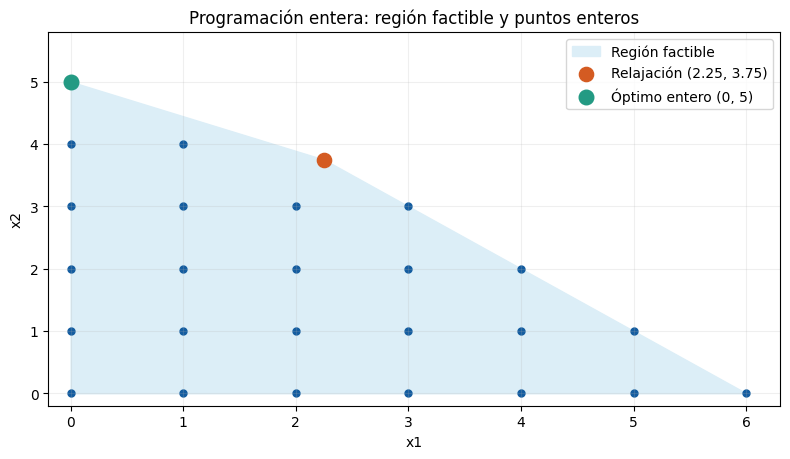

In [4]:
import numpy as np
import matplotlib.pyplot as plt

xs = np.linspace(0,6,300)
ymax = np.maximum(0,np.minimum(6-xs, (45-5*xs)/9))
plt.figure(figsize=(8,4.7))
plt.fill_between(xs,0,ymax,color='#dceef7',label='Región factible')
for x in range(7):
    for y in range(7):
        if x+y <= 6 and 5*x+9*y <= 45:
            plt.scatter(x,y,color='#145da0',s=25)
plt.scatter([2.25],[3.75],color='#d45b22',s=105,zorder=5,label='Relajación (2.25, 3.75)')
plt.scatter([0],[5],color='#239a83',s=110,zorder=6,label='Óptimo entero (0, 5)')
plt.title('Programación entera: región factible y puntos enteros')
plt.xlabel('x1'); plt.ylabel('x2');plt.xlim(-.2,6.3);plt.ylim(-.2,5.8)
plt.legend();plt.grid(alpha=.2);plt.tight_layout();plt.show()

**Resultados verificados:** exploración por niveles: 7 nodos, incumbentes 39 y 40; exploración en profundidad: 7 nodos, primera incumbente 40. En ambos casos el óptimo entero es $(x_1,x_2)=(0,5)$ y $Z=40$. El orden de exploración no altera el óptimo, pero sí puede alterar cuándo se encuentra una solución entera.

<div style="background:#EAF7F2;border-left:5px solid #239A83;padding:10px 14px;margin:10px 0;border-radius:8px"><b style="color:#239A83">Óptimo entero:</b> $x_1=0$, $x_2=5$, $Z=40$; la relajación da $41,25$.</div>

In [5]:
z_relajada = 41.25
z_entera = resultado_niveles[0]
brecha = (z_relajada - z_entera) / z_entera * 100
print(f'Brecha inicial: ({z_relajada:.2f} - {z_entera:.2f}) / {z_entera:.2f} * 100 = {brecha:.3f}%')

Brecha inicial: (41.25 - 40.00) / 40.00 * 100 = 3.125%


**Comprobación adicional con Pyomo y CBC.** Se declaran variables enteras no negativas y se compara el resultado con el algoritmo creado desde cero.

In [6]:
m1 = pyo.ConcreteModel()
m1.x1 = pyo.Var(domain=pyo.NonNegativeIntegers)
m1.x2 = pyo.Var(domain=pyo.NonNegativeIntegers)
m1.z = pyo.Objective(expr=5*m1.x1 + 8*m1.x2, sense=pyo.maximize)
m1.r1 = pyo.Constraint(expr=m1.x1 + m1.x2 <= 6)
m1.r2 = pyo.Constraint(expr=5*m1.x1 + 9*m1.x2 <= 45)
pyo.SolverFactory('cbc').solve(m1)
print('CBC: x1 =', pyo.value(m1.x1), 'x2 =', pyo.value(m1.x2),
      'Z =', pyo.value(m1.z))

CBC: x1 = 0.0 x2 = 5.0 Z = 40.0


<div style="border-left:4px solid #239A83;background:#F0F9F6;padding:7px 12px;margin:12px 0 8px 0"><h3 style="color:#167560;font-size:16px;margin:0">Preguntas respondidas – Actividad 1</h3></div>
**1. ¿Cuántos nodos resuelve la exploración en profundidad y en qué orden aparecen las incumbentes?**
Resuelve **7 nodos**, pero con `pop()` se visita primero la rama derecha. Se encuentra directamente la incumbente $Z=40$ en $(0,5)$; la rama que habría producido $Z=39$ queda podada por cota. Con `pop(0)` aparecen primero $Z=39$ y luego $Z=40$.

**2. ¿Cuál es la brecha entre la relajación (41,25) y el óptimo entero?**
Usando el óptimo entero como denominador: $(41,25-40)/40\times100=\mathbf{3,125\%}$. La relajación da una cota superior que supera al óptimo entero en 1,25 unidades.

**3. ¿Coincide CBC?**
Sí. CBC devuelve $x_1=0$, $x_2=5$, $Z=40$, igual que el algoritmo manual. CBC certifica la solución mediante técnicas de programación entera.

<div style="background:#E9F3FA;border-left:6px solid #145DA0;padding:12px 16px;border-radius:9px;margin:18px 0 10px 0"><h2 style="margin:0;color:#145DA0;font-size:21px">Actividad 2 · Localización de centros de acopio (4 puntos)</h2></div>
**Modelo matemático:** decidir si abrir un centro ($y_i\in\{0,1\}$) y cuánto enviar desde cada centro a cada comunidad ($x_{ij}\ge0$, L/día).

Minimizar costo mensual $\sum_i F_i y_i+30\sum_i\sum_j c_{ij}x_{ij}$, sujeto a $\sum_i x_{ij}=d_j$ para cada comunidad y $\sum_j x_{ij}\le K_i y_i$ para cada centro.

**Datos:** se transcriben de la Tabla 3 de la guía teórica y del Código 3 de la práctica.

In [7]:
import pyomo.environ as pyo

centros = {'Ayaviri': (9000,6000), 'Santa Rosa': (6000,3500),
           'Nunoa': (5000,3000), 'Orurillo': (5500,3200)}
comunidades = {'C1':900, 'C2':1200, 'C3':700,
               'C4':1000, 'C5':800, 'C6':600}
precios = {'Ayaviri':[.05,.06,.10,.12,.09,.14],
           'Santa Rosa':[.08,.05,.07,.15,.13,.11],
           'Nunoa':[.14,.12,.06,.05,.10,.08],
           'Orurillo':[.10,.11,.13,.07,.04,.06]}
I, J = list(centros), list(comunidades)
costo = {(i,j):precios[i][k] for i in I for k,j in enumerate(J)}

def modelo_acopio(entero=True, sin_santa=False, tres=False,
                  fijo_ayaviri=None, logica=False, gran_M=None):
    m = pyo.ConcreteModel()
    m.y = pyo.Var(I, domain=pyo.Binary if entero else pyo.UnitInterval)
    m.x = pyo.Var(I, J, domain=pyo.NonNegativeReals)
    fijo = {i: centros[i][0] for i in I}
    if fijo_ayaviri is not None:
        fijo['Ayaviri'] = fijo_ayaviri
    m.obj = pyo.Objective(expr=sum(fijo[i]*m.y[i] for i in I)
             +30*sum(costo[i,j]*m.x[i,j] for i in I for j in J))
    m.demanda = pyo.Constraint(J,
          rule=lambda m,j: sum(m.x[i,j] for i in I) == comunidades[j])
    m.capacidad = pyo.Constraint(I,
          rule=lambda m,i: sum(m.x[i,j] for j in J)
            <= (gran_M if gran_M is not None else centros[i][1])*m.y[i])
    if sin_santa:
        m.sin_santa = pyo.Constraint(expr=m.y['Santa Rosa'] == 0)
    if tres:
        m.tres = pyo.Constraint(expr=sum(m.y[i] for i in I) == 3)
    if logica:
        m.seguridad = pyo.Constraint(expr=m.y['Ayaviri']
                        +m.y['Nunoa']+m.y['Santa Rosa'] <= 2)
    res = pyo.SolverFactory('cbc').solve(m)
    return m

def resumir(m):
    abiertos = [i for i in I if pyo.value(m.y[i]) > .999]
    return abiertos, round(pyo.value(m.obj),2)

escenarios = [
    ('a) Caso base', {'entero':True}),
    ('b) Relajación lineal', {'entero':False}),
    ('c) Santa Rosa no disponible', {'sin_santa':True}),
    ('d) Exactamente tres centros', {'tres':True}),
    ('e) Ayaviri cuesta S/ 4000', {'fijo_ayaviri':4000})]

for nombre, parametros in escenarios:
    m = modelo_acopio(**parametros)
    usados = [(i,round(pyo.value(m.y[i]),4)) for i in I
               if pyo.value(m.y[i]) > 1e-5]
    print(nombre, '=> Costo S/',round(pyo.value(m.obj),2),'y =',usados)

a) Caso base => Costo S/ 21070.0 y = [('Santa Rosa', 1.0), ('Orurillo', 1.0)]
b) Relajación lineal => Costo S/ 16596.73 y = [('Ayaviri', 0.15), ('Santa Rosa', 0.3429), ('Nunoa', 0.5667), ('Orurillo', 0.4375)]
c) Santa Rosa no disponible => Costo S/ 22050.0 y = [('Nunoa', 1.0), ('Orurillo', 1.0)]
d) Exactamente tres centros => Costo S/ 25260.0 y = [('Santa Rosa', 1.0), ('Nunoa', 1.0), ('Orurillo', 1.0)]
e) Ayaviri cuesta S/ 4000 => Costo S/ 17890.0 y = [('Ayaviri', 1.0)]


<div style="background:#F0F9F6;border-left:5px solid #239A83;padding:9px 13px;margin:9px 0">**Resultado de referencia validado (SciPy/HiGHS):** caso base S/ 21 070; relajación S/ 16 596,73; sin Santa Rosa S/ 22 050; tres centros S/ 25 260; costo de Ayaviri S/ 4 000: S/ 17 890. Estos valores se reproducen con CBC en Colab.</div>

**Tabla 1 completada – escenarios de localización**

| Escenario | Centros abiertos / valores de y | Costo mensual (S/) |
|---|---|---:|
| a) Caso base entero | Santa Rosa y Orurillo | 21 070,00 |
| b) Relajación lineal | Ayaviri 0,1500; Santa Rosa 0,3429; Nuñoa 0,5667; Orurillo 0,4375 | 16 596,73 |
| c) Santa Rosa no disponible | Nuñoa y Orurillo | 22 050,00 |
| d) Exactamente tres centros | Santa Rosa, Nuñoa y Orurillo | 25 260,00 |
| e) Ayaviri cuesta S/ 4 000 | Ayaviri | 17 890,00 |

En la relajación no hay “centros abiertos” de forma real: los valores de $y$ son fracciones matemáticas, no decisiones operativas.

<div style="background:#EAF7F2;border-left:5px solid #239A83;padding:10px 14px;margin:10px 0;border-radius:8px"><b style="color:#239A83">Localización óptima:</b> Santa Rosa y Orurillo · **S/ 21 070 por mes**.</div>

In [8]:
base = pyo.value(modelo_acopio().obj)
lp = pyo.value(modelo_acopio(entero=False).obj)
brecha_acopio = (base-lp)/base*100
print(f'Brecha inicial: {brecha_acopio:.2f}%')
logica = modelo_acopio(logica=True)
print('Con implicación lógica:', resumir(logica))
mal_M = modelo_acopio(entero=False, gran_M=1_000_000)
print('Relajación con M=1 000 000: S/',round(pyo.value(mal_M.obj),2))

Brecha inicial: 21.23%
Con implicación lógica: (['Santa Rosa', 'Orurillo'], 21070.0)
Relajación con M=1 000 000: S/ 7981.5


<div style="border-left:4px solid #239A83;background:#F0F9F6;padding:7px 12px;margin:12px 0 8px 0"><h3 style="color:#167560;font-size:16px;margin:0">Preguntas respondidas – Actividad 2</h3></div>
**1. ¿Cuál es la brecha y qué indica?**
$(21\,070-16\,596,73)/21\,070\times100=\mathbf{21,23\%}$. La relajación subestima el costo entero en S/ 4 473,27; las decisiones binarias y los costos fijos crean una diferencia importante. Una cota más cercana al óptimo suele facilitar su certificación.

**2. Si se abren Ayaviri y Nuñoa, no se puede abrir Santa Rosa. ¿Cambia la solución?**
Se agrega $y_{Ayaviri}+y_{Nuñoa}+y_{SantaRosa}\le2$. **No cambia:** el óptimo original abre Santa Rosa y Orurillo, de modo que satisface esa condición (0+0+1≤2). Permanece en S/ 21 070.

**3. ¿Qué ocurre si M = 1 000 000 en la relajación?**
El costo relajado cae de **S/ 16 596,73** a **S/ 7 981,50**. Con un límite artificial tan alto se puede transportar todo con valores de apertura cercanos a cero, pagando fracciones ínfimas de los costos fijos. La cota se debilita y puede complicar la ramificación. Debe usarse la capacidad real $K_i$ como M.

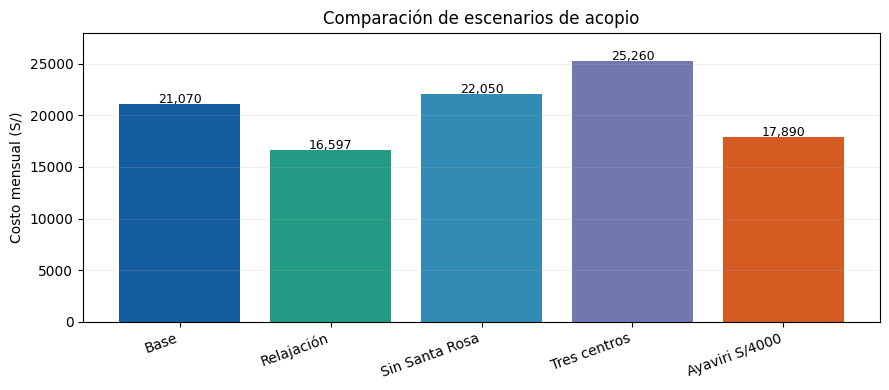

In [9]:
etiquetas = ['Base', 'Relajación','Sin Santa Rosa','Tres centros','Ayaviri S/4000']
valores = [21070,16596.73,22050,25260,17890]
plt.figure(figsize=(9,4))
barras = plt.bar(etiquetas,valores,color=['#145da0','#239a83','#318bb5','#7078ae','#d45b22'])
for barra, valor in zip(barras,valores):
    plt.text(barra.get_x()+barra.get_width()/2, valor+150, f'{valor:,.0f}', ha='center',fontsize=9)
plt.ylabel('Costo mensual (S/)')
plt.title('Comparación de escenarios de acopio')
plt.xticks(rotation=20,ha='right')
plt.grid(axis='y',alpha=.2)
plt.ylim(0,28000)
plt.tight_layout()
plt.show()

<div style="background:#E9F3FA;border-left:6px solid #145DA0;padding:12px 16px;border-radius:9px;margin:18px 0 10px 0"><h2 style="margin:0;color:#145DA0;font-size:21px">Actividad 3 · Condiciones KKT con Ipopt (4 puntos)</h2></div>
Minimizar $f(x)=(x_1-3)^2+(x_2-2)^2$ con $x_1+x_2\le b$.

Para $b<5$, la solución es $x_1=(b+1)/2$, $x_2=(b-1)/2$, $f^*=(5-b)^2/2$ y $\mu=5-b$. Si $b\ge5$, la solución libre $(3,2)$ es factible, con $f^*=\mu=0$.

**Las cuatro condiciones KKT:** estacionariedad, factibilidad primal, factibilidad dual y holgura complementaria.

In [10]:
import pyomo.environ as pyo

def resolver_kkt(b):
    m = pyo.ConcreteModel()
    m.x1 = pyo.Var(initialize=2.5)
    m.x2 = pyo.Var(initialize=1.5)
    m.f = pyo.Objective(expr=(m.x1-3)**2+(m.x2-2)**2)
    m.g = pyo.Constraint(expr=m.x1+m.x2 <= b)
    m.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)
    pyo.SolverFactory('ipopt').solve(m)
    x1 = pyo.value(m.x1)
    x2 = pyo.value(m.x2)
    mu = -m.dual[m.g]  # convención de signos de la guía
    return x1,x2,pyo.value(m.f),mu

for b in [3,4,4.5,6]:
    x1,x2,f,mu = resolver_kkt(b)
    print(f'b={b:3} x1={x1:.4f}, x2={x2:.4f}, f*={f:.4f}, mu={mu:.4f}')

x1,x2,f,mu = resolver_kkt(4)
print('Estacionariedad:',[round(2*(x1-3)+mu,6),round(2*(x2-2)+mu,6)])
print('Factibilidad primal:',x1+x2-4<=1e-6)
print('Factibilidad dual:',mu>=-1e-8)
print('Holgura complementaria:',round(mu*(x1+x2-4),8))

b=  3 x1=2.0000, x2=1.0000, f*=2.0000, mu=2.0000
b=  4 x1=2.5000, x2=1.5000, f*=0.5000, mu=1.0000
b=4.5 x1=2.7500, x2=1.7500, f*=0.1250, mu=0.5000
b=  6 x1=3.0000, x2=2.0000, f*=0.0000, mu=0.0000
Estacionariedad: [0.0, 0.0]
Factibilidad primal: True
Factibilidad dual: True
Holgura complementaria: 4e-08


<div style="background:#F0F9F6;border-left:5px solid #239A83;padding:9px 13px;margin:9px 0">**Resultado de referencia analítico:** para $b=3,4,4.5,6$ las soluciones $(x_1,x_2,f,\mu)$ son $(2,1,2,2)$; $(2.5,1.5,0.5,1)$; $(2.75,1.75,0.125,0.5)$; $(3,2,0,0)$. La verificación KKT da residuos cero.</div>

**Tabla 2 completada – sensibilidad KKT**

| Lado derecho $b$ | $x_1^*$ | $x_2^*$ | $f^*$ | $\mu$ |
|---:|---:|---:|---:|---:|
| 3 | 2,0 | 1,0 | 2,0 | 2,0 |
| 4 | 2,5 | 1,5 | 0,5 | 1,0 |
| 4,5 | 2,75 | 1,75 | 0,125 | 0,5 |
| 6 | 3,0 | 2,0 | 0,0 | 0,0 |

<div style="background:#EAF7F2;border-left:5px solid #239A83;padding:10px 14px;margin:10px 0;border-radius:8px"><b style="color:#239A83">Condiciones KKT:</b> En $b=4$: solución $(2,5;1,5)$, $f^*=0,5$ y $\mu=1$.</div>

<div style="border-left:4px solid #239A83;background:#F0F9F6;padding:7px 12px;margin:12px 0 8px 0"><h3 style="color:#167560;font-size:16px;margin:0">Preguntas respondidas – Actividad 3</h3></div>
**1. Compare el cambio de $f^*$ entre $b=4$ y $b=4,5$ con $\mu\delta$. ¿Por qué no coincide exactamente?**
El cambio real es $0,125-0,5=-0,375$. La aproximación de primer orden usando el multiplicador inicial $\mu=1$ y $\delta=0,5$ es $-\mu\delta=-0,5$. No coincide porque $\mu$ no es constante en todo el intervalo: disminuye de 1 a 0,5. El precio sombra es una tasa **marginal**, no una variación exacta para cambios finitos.

**2. ¿Por qué $\mu=0$ cuando $b=6$?**
El mínimo sin restricción es $(3,2)$ y cumple $3+2=5<6$. La restricción tiene holgura 1 y deja de limitar la decisión, por lo que la holgura complementaria exige $\mu=0$.

<div style="background:#E9F3FA;border-left:6px solid #145DA0;padding:12px 16px;border-radius:9px;margin:18px 0 10px 0"><h2 style="margin:0;color:#145DA0;font-size:21px">Actividad 4 · Presupuesto de marketing no lineal (4 puntos)</h2></div>
Maximizar $30\ln(1+x_{radio})+50\ln(1+x_{redes})+20\ln(1+x_{ferias})$, sujeto a $x_{radio}+x_{redes}+x_{ferias}\le B$, $x_k\ge0$. Los presupuestos $x_k$ se expresan en **miles de soles**.

La condición de rendimientos marginales para los canales con inversión positiva es $a_k/(1+x_k)=\lambda$.

Presupuesto de S/10 000 (en miles): {'radio': 2.900000029775772, 'redes': 5.5000000492810885, 'ferias': 1.600000020617342}
Margen: 153.5296 lambda: 7.6923


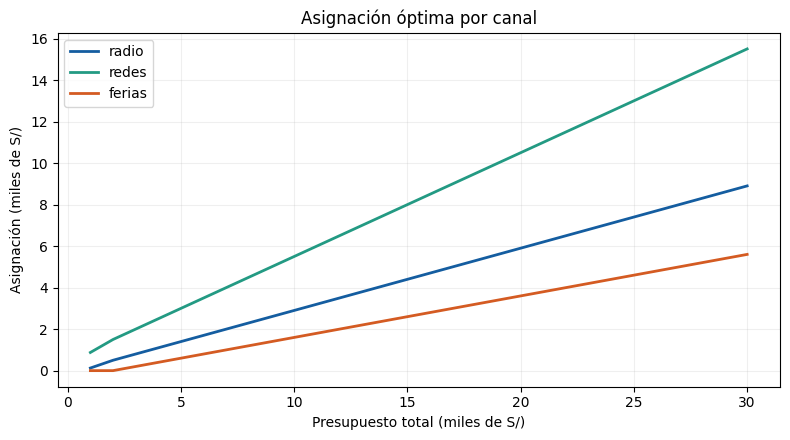

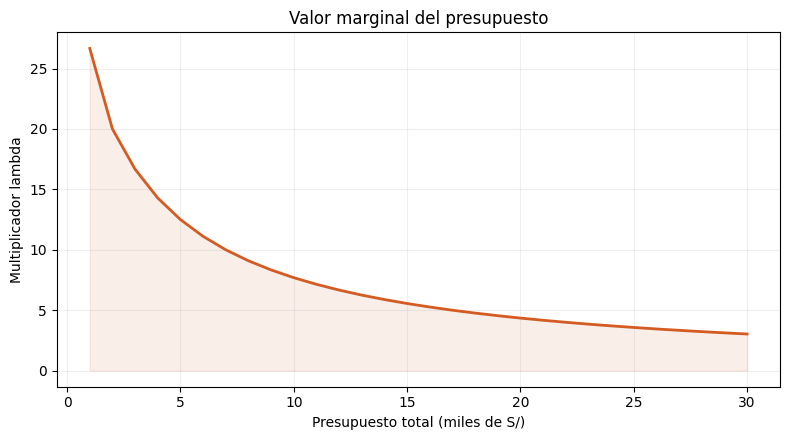

Primer presupuesto entero (en miles) con ferias > 0: 3


In [11]:
import pyomo.environ as pyo
import matplotlib.pyplot as plt

a = {'radio':30,'redes':50,'ferias':20}

def marketing(B, minimo_ferias=0):
    m = pyo.ConcreteModel()
    m.x = pyo.Var(a,domain=pyo.NonNegativeReals,initialize=1)
    m.obj = pyo.Objective(expr=sum(a[k]*pyo.log(1+m.x[k]) for k in a),
                          sense=pyo.maximize)
    m.pres = pyo.Constraint(expr=sum(m.x[k] for k in a)<=B)
    m.ferias_min = pyo.Constraint(expr=m.x['ferias']>=minimo_ferias)
    m.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)
    pyo.SolverFactory('ipopt').solve(m)
    reparto = {k:max(0,pyo.value(m.x[k])) for k in a}
    return reparto,pyo.value(m.obj),abs(m.dual[m.pres])

reparto,margen,lam = marketing(10)
print('Presupuesto de S/10 000 (en miles):',reparto)
print('Margen:',round(margen,4),'lambda:',round(lam,4))

presupuestos = list(range(1,31))
repartos = []
lambdas = []
for B in presupuestos:
    x,valor,precio_sombra = marketing(B)
    repartos.append(x)
    lambdas.append(precio_sombra)

paleta = {'radio':'#145da0','redes':'#239a83','ferias':'#d45b22'}
plt.figure(figsize=(8,4.5))
for k in a:
    plt.plot(presupuestos,[x[k] for x in repartos],label=k,color=paleta[k],linewidth=2)
plt.xlabel('Presupuesto total (miles de S/)')
plt.ylabel('Asignación (miles de S/)')
plt.title('Asignación óptima por canal')
plt.legend();plt.grid(alpha=.2);plt.tight_layout();plt.show()

plt.figure(figsize=(8,4.5))
plt.plot(presupuestos,lambdas,color='#d45b22',linewidth=2)
plt.fill_between(presupuestos,lambdas,color='#d45b22',alpha=.10)
plt.xlabel('Presupuesto total (miles de S/)')
plt.ylabel('Multiplicador lambda')
plt.title('Valor marginal del presupuesto')
plt.grid(alpha=.2);plt.tight_layout();plt.show()

primer_B = next(B for B,x in zip(presupuestos,repartos) if x['ferias']>0.001)
print('Primer presupuesto entero (en miles) con ferias > 0:',primer_B)

<div style="background:#F0F9F6;border-left:5px solid #239A83;padding:9px 13px;margin:9px 0">**Resultado de referencia analítico:** con S/ 10 000: radio 2,9; redes 5,5; ferias 1,6 (miles de soles). Margen $153,529634$ y $\lambda=7,692308$. Ferias recibe inversión para $B>2$ miles de soles.</div>

In [12]:
x_sin, margen_sin, _ = marketing(10)
x_con, margen_con, _ = marketing(10, minimo_ferias=2)
print('Sin convenio:',x_sin,'margen:',round(margen_sin,6))
print('Con ferias al menos S/ 2000:',x_con,'margen:',round(margen_con,6))
print('Pérdida de margen:',round(margen_sin-margen_con,6))

# Ejercicio opcional: precio óptimo de una chalina
m = pyo.ConcreteModel()
m.p = pyo.Var(bounds=(18,50),initialize=30)
m.u = pyo.Objective(expr=(m.p-18)*(400-8*m.p),sense=pyo.maximize)
pyo.SolverFactory('ipopt').solve(m)
print('Chalina: precio óptimo S/',round(pyo.value(m.p),2),
      'utilidad semanal S/',round(pyo.value(m.u),2))

Sin convenio: {'radio': 2.900000029775772, 'redes': 5.5000000492810885, 'ferias': 1.600000020617342} margen: 153.529635
Con ferias al menos S/ 2000: {'radio': 2.750000044303285, 'redes': 5.250000073499767, 'ferias': 1.9999999818836567} margen: 153.253995
Pérdida de margen: 0.27564
Chalina: precio óptimo S/ 34.0 utilidad semanal S/ 2048.0


<div style="background:#F0F9F6;border-left:5px solid #239A83;padding:9px 13px;margin:9px 0">**Resultado de referencia analítico:** con ferias $\ge2$ miles, radio $2,75$, redes $5,25$, ferias $2,00$; margen $153,253994$, reducción $0,275640$. Chalina: $p^*=34$, $U^*=2 048$.</div>

<div style="border-left:4px solid #239A83;background:#F0F9F6;padding:7px 12px;margin:12px 0 8px 0"><h3 style="color:#167560;font-size:16px;margin:0">Preguntas respondidas – Actividad 4</h3></div>
**1. ¿A partir de qué presupuesto recibe dinero el canal de ferias?**
Ferias empieza a recibir inversión cuando $\lambda<20$. Justo antes de entrar, los otros dos canales tienen $x_{radio}=30/20-1=0,5$ y $x_{redes}=50/20-1=1,5$. Sumados dan **B=2** miles de soles. Por tanto, **ferias recibe inversión positiva cuando B>2 (más de S/ 2 000)**; en la gráfica para presupuestos enteros, desde **S/ 3 000**.

**2. ¿Cómo cambia $\lambda$ al aumentar el presupuesto?**
Disminuye, porque todos los canales presentan rendimientos decrecientes. En $B=10$, $\lambda=100/13\approx7,6923$. Para gerencia representa el margen adicional aproximado que aporta aumentar el presupuesto en una unidad (S/ 1 000); el beneficio marginal se reduce al asignar más fondos.

**3. Si se exigen S/ 2 000 en ferias, ¿cuánto margen se pierde?**
Sin convenio: radio 2,9; redes 5,5; ferias 1,6; margen **153,529634**. Con el mínimo: radio 2,75; redes 5,25; ferias 2; margen **153,253994**. La pérdida es **0,275640 unidades del margen modelado**. Es importante no presentar esa magnitud como soles porque la guía no especifica unidades monetarias para el valor de la función de margen.

**4. Opcional – chalina.**
Si $U(p)=(p-18)(400-8p)$, entonces $U'(p)=544-16p$. Igualando a cero se obtiene $p=34$ y $U(34)=2048$. Ipopt reproduce el **precio óptimo de S/ 34** y utilidad semanal de **S/ 2 048**.

<div style="background:#E9F3FA;border-left:6px solid #145DA0;padding:12px 16px;border-radius:9px;margin:18px 0 10px 0"><h2 style="margin:0;color:#145DA0;font-size:21px">Actividad 5 · Proyecto integrador: versión entera (4 puntos)</h2></div>

**Continuidad real de la Práctica 2:** **«Optimización de la distribución de la capacidad operativa del personal de una Mesa de Servicios de TI»**.

**Datos de referencia:** 1 655 tickets de atención general, 1 224 de aplicaciones, 7 colaboradores (4 y 3 en la versión inicial), 172 horas mensuales por colaborador. Los tiempos por ticket de 0,40 h y 0,50 h son **supuestos para el modelo**, no datos históricos medidos.

**Variables:** $X_G$, $X_A$ tickets enteros; $y_k\in\{0,1\}$ indica si el colaborador $k$ queda en atención general (1) o aplicaciones (0).

**Objetivo y restricciones:**

$$\max Z=X_G+X_A$$
$$0.40X_G\le172\sum_{k=1}^7y_k$$
$$0.50X_A\le172\left(7-\sum_{k=1}^7y_k\right)$$
$$X_G\le1655,\quad X_A\le1224.$$

El escenario de **personal fijo de la Práctica 2** atiende 2 687 tickets. En esta práctica se agrega la posibilidad de reasignar colaboradores y se compara el resultado continuo y entero; el cálculo se desarrolla en las celdas siguientes.

In [13]:
import pyomo.environ as pyo
import time

def proyecto_csti(entero=True):
    m=pyo.ConcreteModel()
    m.K=pyo.RangeSet(1,7)
    dom=pyo.Binary if entero else pyo.UnitInterval
    m.y=pyo.Var(m.K, domain=dom)
    dom_t=pyo.NonNegativeIntegers if entero else pyo.NonNegativeReals
    m.XG=pyo.Var(domain=dom_t)
    m.XA=pyo.Var(domain=dom_t)
    m.obj=pyo.Objective(expr=m.XG+m.XA,sense=pyo.maximize)
    m.capG=pyo.Constraint(expr=0.40*m.XG <= 172*sum(m.y[k] for k in m.K))
    m.capA=pyo.Constraint(expr=0.50*m.XA <= 172*sum(1-m.y[k] for k in m.K))
    m.demG=pyo.Constraint(expr=m.XG <= 1655)
    m.demA=pyo.Constraint(expr=m.XA <= 1224)
    t0=time.perf_counter()
    res=pyo.SolverFactory('cbc').solve(m)
    return m, res, time.perf_counter()-t0

for entero in (False,True):
    m,res,t=proyecto_csti(entero)
    print('ENTERO' if entero else 'RELAJADO',pyo.value(m.obj),
          round(sum(pyo.value(m.y[k]) for k in m.K),4),
          'segundos:',round(t,4),'estado:',res.solver.termination_condition)
m_LP,rs_LP,t_LP=proyecto_csti(False)
m_IP,rs_IP,t_IP=proyecto_csti(True)
Z_lp=pyo.value(m_LP.obj)
Z_ip=pyo.value(m_IP.obj)
print('Brecha inicial (%):',round((Z_lp-Z_ip)/Z_ip*100,2))
print('Brecha final:',0 if str(rs_IP.solver.termination_condition).lower()=='optimal' else 'Verificar')


RELAJADO 2739.0 3.8488 segundos: 0.0438 estado: optimal
ENTERO 2687.0 4.0 segundos: 0.0463 estado: optimal
Brecha inicial (%): 1.94
Brecha final: 0


<div style="background:#F0F9F6;border-left:5px solid #239A83;padding:9px 13px;margin:9px 0">**Resultado de referencia validado (SciPy/HiGHS):** proyecto CSTI: LP ampliada = **2 739 tickets**, entero = **2 687 tickets**, distribución óptima = **4 general + 3 aplicaciones**. Brecha inicial $1,94\%$. El tiempo exacto y el estado CBC se muestran al ejecutar la celda anterior en Google Colab.</div>

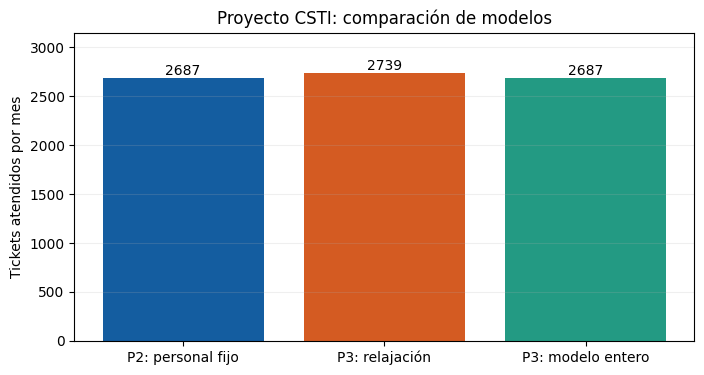

In [14]:
import matplotlib.pyplot as plt
valores=[2687,2739,2687]
etiquetas=['P2: personal fijo','P3: relajación','P3: modelo entero']
fig,ax=plt.subplots(figsize=(8,4))
barras=ax.bar(etiquetas,valores,color=['#145da0','#d45b22','#239a83'])
for barra,v in zip(barras,valores):
    ax.text(barra.get_x()+barra.get_width()/2,v+30,str(v),ha='center')
ax.set_ylim(0,3150)
ax.set_ylabel('Tickets atendidos por mes')
ax.set_title('Proyecto CSTI: comparación de modelos')
ax.grid(axis='y',alpha=.2)
plt.show()

<div style="background:#E9F3FA;border-left:5px solid #145DA0;padding:11px 15px"><h3 style="color:#145DA0;margin:0">Actividad 5. Proyecto integrador: Mesa de Servicios TI (CSTI)</h3></div>

La práctica 2 utiliza los datos de **octubre de 2026 (2 879 tickets)**: 1 655 de atención general y 1 224 de aplicaciones, 4 y 3 colaboradores respectivamente, con 172 horas mensuales. Los tiempos 0,40 y 0,50 h/ticket son **supuestos de prueba** que deben validarse.

| Elemento | Desarrollo |
|---|---|
| Variables | $X_G,X_A$ enteros: tickets atendidos; $y_k$ binaria para asignar a cada uno de los 7 colaboradores a atención general (1) o aplicaciones (0) |
| Objetivo | Maximizar $Z=X_G+X_A$ |
| Restricciones | $0.40X_G\le172\sum_k y_k$, $0.50X_A\le172(7-\sum_k y_k)$; $X_G\le1655$, $X_A\le1224$ |
| Modelo de la práctica 2 | Con 4/3 colaboradores fijos: 2 687 tickets (solución continua que también es entera) |
| Nueva relajación | Al permitir redistribuir personal fraccionalmente: 2 739 tickets (cota superior) |
| Modelo entero | 2 687 tickets con 4 colaboradores en general y 3 en aplicaciones |
| Brecha inicial | $(2739-2687)/2687\times100=1,94\%$ |
| Brecha final | 0 % cuando CBC termina en estado `optimal` |
| Tiempo del modelo | Se obtiene realmente al ejecutar en Colab: no se inventan tiempos |
| No linealidad | El modelo es lineal; la saturación podría requerir linealización por tramos |

**Nota:** esta propuesta continúa la versión lineal real de la práctica 2, no el ejemplo genérico de servidores.

---
### Conclusiones
1. Ramificación y acotamiento encuentra el óptimo entero sin recurrir al redondeo.
2. Los costos fijos y las variables binarias hacen que la relajación lineal subestime el costo real de apertura de centros.
3. Las condiciones KKT identifican multiplicadores con interpretación marginal y muestran cuándo una restricción deja de ser activa.
4. En marketing, el multiplicador disminuye con el presupuesto por rendimientos decrecientes.
5. El proyecto de la Mesa de Servicios TI mantiene 2 687 tickets en su solución entera, frente a la cota de 2 739 tickets de la relajación del modelo ampliado.

**Fuente:** Guía de Práctica N.° 03 y Guía Teórica N.° 03 del curso MIS202, Universidad Nacional del Altiplano. Los datos son académicos/ilustrativos, según las guías.